In [24]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [25]:
url = "https://query1.finance.yahoo.com/v8/finance/chart/TMCV.NS?range=1d&interval=1m"

headers = {"User-Agent": "Mozilla/5.0"}

response = requests.get(url, headers=headers)
response.raise_for_status()

data = response.json()

result = data["chart"]["result"][0]

print(result.keys())



dict_keys(['meta', 'timestamp', 'indicators'])


In [26]:
quote = result["indicators"]["quote"][0]

df = pd.DataFrame({
    "Date": pd.to_datetime(
        result["timestamp"], unit="s", utc=True
    ).tz_convert("Asia/Kolkata"),
    "Open": quote["open"],
    "High": quote["high"],
    "Low": quote["low"],
    "Close": quote["close"],
    "Volume": quote["volume"]
})

df = df.dropna(subset=["Close"])

print(df.tail(10))


                        Date        Open        High         Low       Close  \
79 2026-11-17 10:34:00+05:30  445.200012  445.200012  445.100006  445.100006   
80 2026-11-17 10:35:00+05:30  445.200012  445.500000  445.200012  445.399994   
81 2026-11-17 10:36:00+05:30  445.399994  445.500000  445.250000  445.250000   
82 2026-11-17 10:37:00+05:30  445.250000  445.649994  445.250000  445.649994   
83 2026-11-17 10:38:00+05:30  445.649994  445.649994  445.399994  445.450012   
84 2026-11-17 10:39:00+05:30  445.450012  445.500000  445.350006  445.450012   
85 2026-11-17 10:40:00+05:30  445.500000  445.649994  445.450012  445.500000   
86 2026-11-17 10:41:00+05:30  445.649994  445.649994  445.450012  445.549988   
87 2026-11-17 10:42:00+05:30  445.549988  445.700012  445.549988  445.700012   
89 2026-11-17 10:43:54+05:30  445.649994  445.649994  445.649994  445.649994   

     Volume  
79  19745.0  
80  24084.0  
81  16315.0  
82  29009.0  
83  14048.0  
84  11125.0  
85  13991.0  
86  206

In [27]:
prices = df["Close"].to_numpy()

print("Latest Price:", prices[-1])
print("Average Price:", np.mean(prices))
print("Maximum Price:", np.max(prices))
print("Minimum Price:", np.min(prices))
print("Standard Deviation:", np.std(prices))


Latest Price: 445.6499938964844
Average Price: 443.5224732816889
Maximum Price: 446.1499938964844
Minimum Price: 434.20001220703125
Standard Deviation: 2.4421265778197503


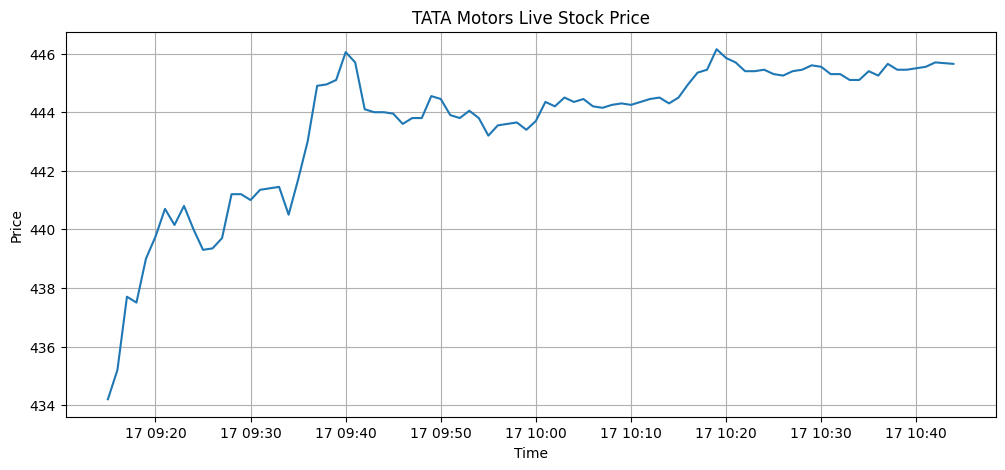

In [28]:
plt.figure(figsize=(12,5))
plt.plot(df["Date"], df["Close"])
plt.title("TATA Motors Live Stock Price")
plt.xlabel("Time")
plt.ylabel("Price")
plt.grid()
plt.show()


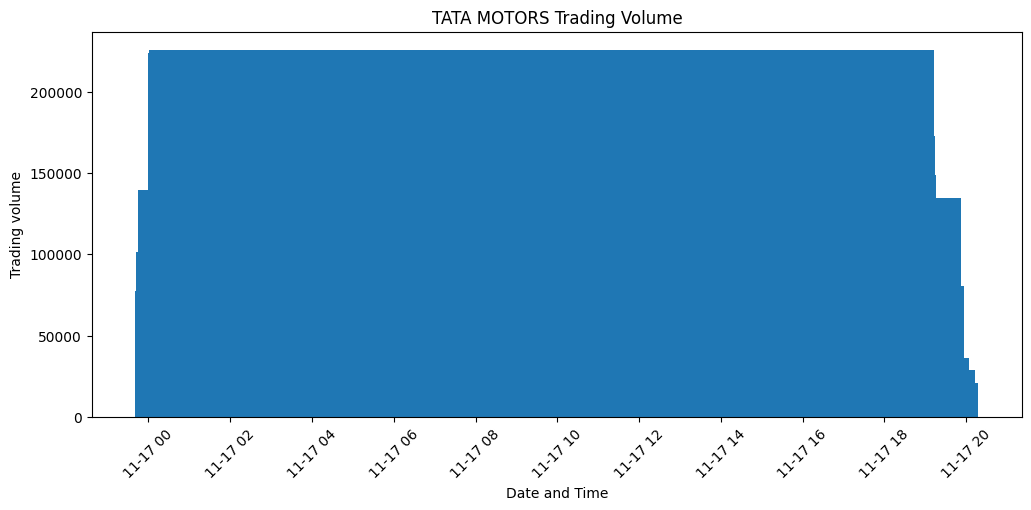

In [29]:
plt.figure(figsize=(12,5))
plt.bar(df["Date"], df["Volume"])
plt.title("TATA MOTORS Trading Volume")
plt.xlabel("Date and Time")
plt.ylabel("Trading volume")
plt.xticks(rotation=45)
plt.show()

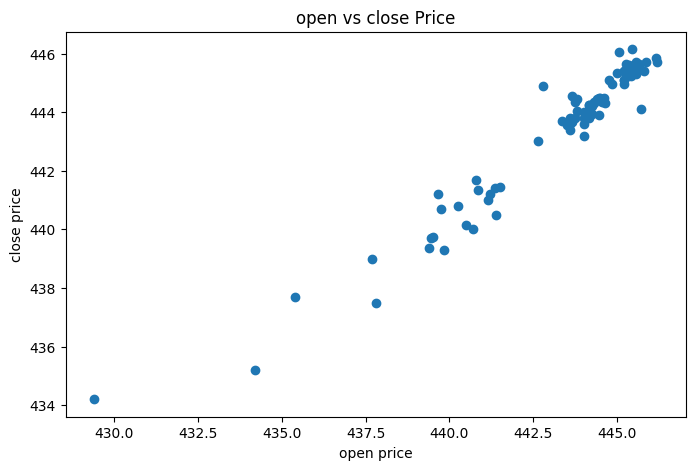

In [30]:
plt.figure(figsize=(8,5))
plt.scatter(df["Open"],df["Close"])
plt.title("open vs close Price")
plt.xlabel("open price")
plt.ylabel("close price")
plt.show()

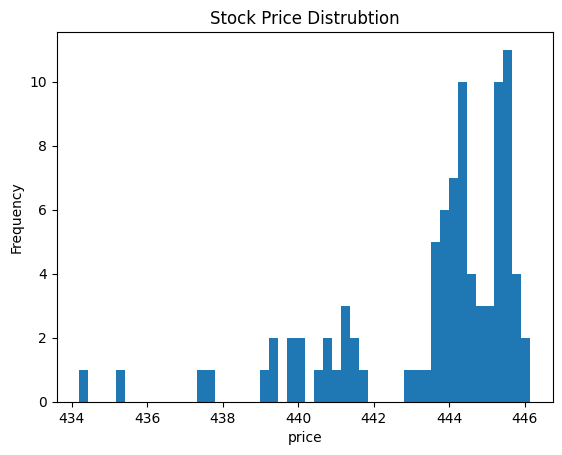

In [31]:
plt.hist(df["Close"],bins=50)
plt.title("Stock Price Distrubtion")
plt.xlabel("price")
plt.ylabel("Frequency")
plt.show()

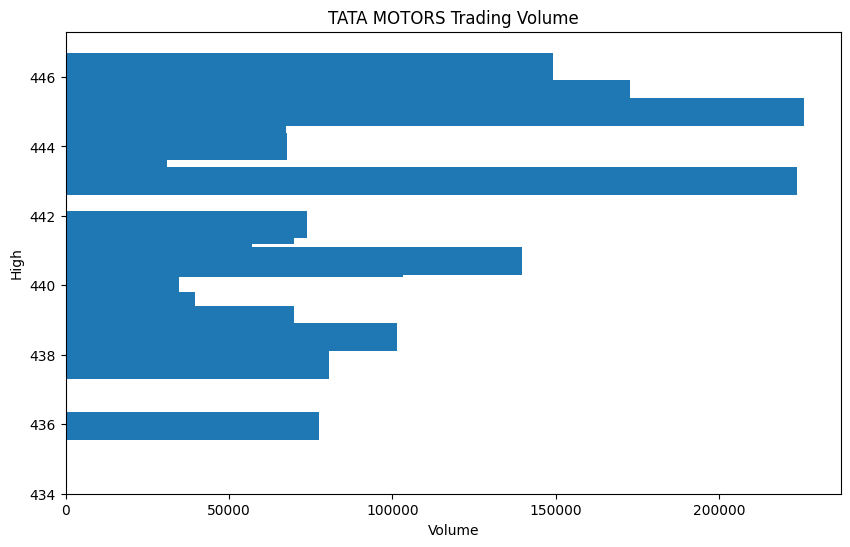

In [32]:
plt.figure(figsize=(10,6))
plt.barh(df["High"],df['Volume'])
plt.title("TATA MOTORS Trading Volume")
plt.xlabel("Volume")
plt.ylabel("High")
plt.show()

In [33]:
df.describe()

,Open,High,Low,Close,Volume
count,89.000000,89.000000,89.000000,89.000000,89.000000
mean,443.373596,443.766292,443.091011,443.522473,44237.752809
std,2.846310,2.364290,2.868992,2.455963,43465.613869
min,429.399994,435.000000,429.399994,434.200012,0.000000
25%,442.799988,443.549988,442.750000,443.200012,17241.000000
50%,444.250000,444.450012,444.000000,444.299988,29380.000000
75%,445.250000,445.500000,445.100006,445.299988,54268.000000
max,446.200012,446.299988,445.649994,446.149994,225825.000000


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 89 entries, 0 to 89
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype                       
---  ------  --------------  -----                       
 0   Date    89 non-null     datetime64[ns, Asia/Kolkata]
 1   Open    89 non-null     float64                     
 2   High    89 non-null     float64                     
 3   Low     89 non-null     float64                     
 4   Close   89 non-null     float64                     
 5   Volume  89 non-null     float64                     
dtypes: datetime64[ns, Asia/Kolkata](1), float64(5)
memory usage: 4.9 KB


In [35]:
df.isnull().sum()

,0
Date,0
Open,0
High,0
Low,0
Close,0
Volume,0


In [36]:
df.head()

,Date,Open,High,Low,Close,Volume
0,2026-11-17 09:15:00+05:30,429.399994,435.000000,429.399994,434.200012,0.0
1,2026-11-17 09:16:00+05:30,434.200012,435.950012,433.649994,435.200012,77559.0
2,2026-11-17 09:17:00+05:30,435.399994,437.700012,434.799988,437.700012,80452.0
3,2026-11-17 09:18:00+05:30,437.799988,438.500000,437.500000,437.500000,101245.0
4,2026-11-17 09:19:00+05:30,437.700012,439.000000,437.399994,439.000000,69987.0


In [37]:
df.tail()

,Date,Open,High,Low,Close,Volume
84,2026-11-17 10:39:00+05:30,445.450012,445.500000,445.350006,445.450012,11125.0
85,2026-11-17 10:40:00+05:30,445.500000,445.649994,445.450012,445.500000,13991.0
86,2026-11-17 10:41:00+05:30,445.649994,445.649994,445.450012,445.549988,20692.0
87,2026-11-17 10:42:00+05:30,445.549988,445.700012,445.549988,445.700012,15143.0
89,2026-11-17 10:43:54+05:30,445.649994,445.649994,445.649994,445.649994,0.0


In [38]:
df.shape

(89, 6)

In [39]:
high_price=df[df["Close"]>460]
print(high_price)

Empty DataFrame
Columns: [Date, Open, High, Low, Close, Volume]
Index: []


In [40]:
df.sort_values(by="Open",ascending=False)

,Date,Open,High,Low,Close,Volume
26,2026-11-17 09:41:00+05:30,446.200012,446.200012,445.450012,445.700012,53975.0
65,2026-11-17 10:20:00+05:30,446.149994,446.149994,445.299988,445.850006,54268.0
66,2026-11-17 10:21:00+05:30,445.850006,445.899994,445.299988,445.700012,80340.0
67,2026-11-17 10:22:00+05:30,445.799988,445.799988,445.399994,445.399994,20494.0
27,2026-11-17 09:42:00+05:30,445.700012,445.850006,443.000000,444.100006,101487.0
...,...,...,...,...,...,...
3,2026-11-17 09:18:00+05:30,437.799988,438.500000,437.500000,437.500000,101245.0
4,2026-11-17 09:19:00+05:30,437.700012,439.000000,437.399994,439.000000,69987.0
2,2026-11-17 09:17:00+05:30,435.399994,437.700012,434.799988,437.700012,80452.0
1,2026-11-17 09:16:00+05:30,434.200012,435.950012,433.649994,435.200012,77559.0


In [41]:
df["Price_Diff"]=df["High"]-df["Low"]
df["Daily_change"]=df["Close"]-df["Open"]
print(df)

                        Date        Open        High         Low       Close  \
0  2026-11-17 09:15:00+05:30  429.399994  435.000000  429.399994  434.200012   
1  2026-11-17 09:16:00+05:30  434.200012  435.950012  433.649994  435.200012   
2  2026-11-17 09:17:00+05:30  435.399994  437.700012  434.799988  437.700012   
3  2026-11-17 09:18:00+05:30  437.799988  438.500000  437.500000  437.500000   
4  2026-11-17 09:19:00+05:30  437.700012  439.000000  437.399994  439.000000   
..                       ...         ...         ...         ...         ...   
84 2026-11-17 10:39:00+05:30  445.450012  445.500000  445.350006  445.450012   
85 2026-11-17 10:40:00+05:30  445.500000  445.649994  445.450012  445.500000   
86 2026-11-17 10:41:00+05:30  445.649994  445.649994  445.450012  445.549988   
87 2026-11-17 10:42:00+05:30  445.549988  445.700012  445.549988  445.700012   
89 2026-11-17 10:43:54+05:30  445.649994  445.649994  445.649994  445.649994   

      Volume  Price_Diff  Daily_change 

In [42]:
df.loc[df["High"].idxmax()]

,25
Date,2026-11-17 09:40:00+05:30
Open,445.049988
High,446.299988
Low,445.0
Close,446.049988
Volume,149146.0
Price_Diff,1.299988
Daily_change,1.0


In [43]:
df.loc[df["Low"].idxmin()]

,0
Date,2026-11-17 09:15:00+05:30
Open,429.399994
High,435.0
Low,429.399994
Close,434.200012
Volume,0.0
Price_Diff,5.600006
Daily_change,4.800018


In [44]:
df[["High","Low","Close"]]

,High,Low,Close
0,435.000000,429.399994,434.200012
1,435.950012,433.649994,435.200012
2,437.700012,434.799988,437.700012
3,438.500000,437.500000,437.500000
4,439.000000,437.399994,439.000000
...,...,...,...
84,445.500000,445.350006,445.450012
85,445.649994,445.450012,445.500000
86,445.649994,445.450012,445.549988
87,445.700012,445.549988,445.700012


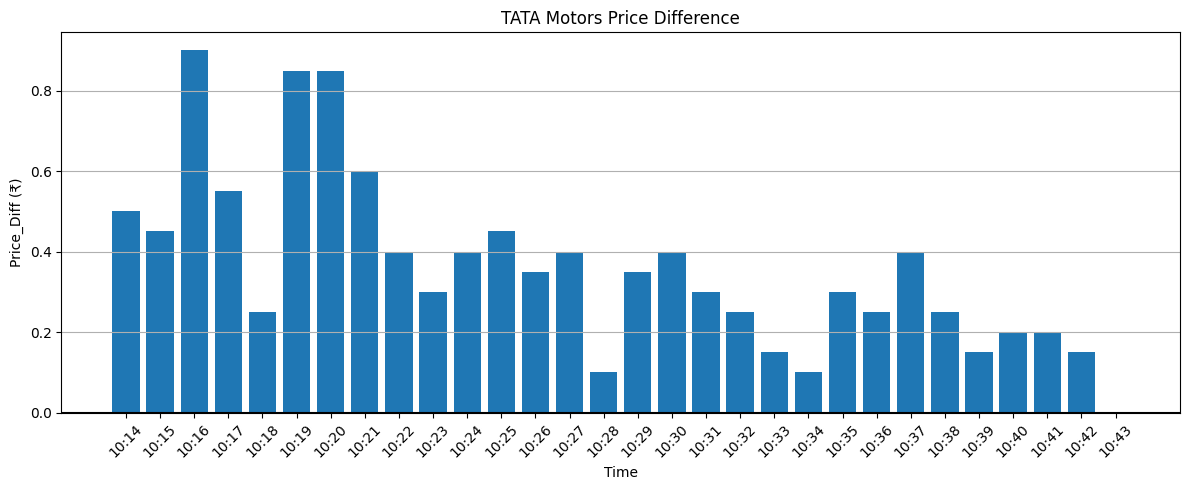

In [45]:
last_15=df.tail(30)
plt.figure(figsize=(12,5))

plt.bar(
    last_15["Date"].dt.strftime("%H:%M"),
    last_15["Price_Diff"]
)

plt.axhline(y=0, color="black")

plt.title("TATA Motors Price Difference")
plt.xlabel("Time")
plt.ylabel("Price_Diff (₹)")

plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

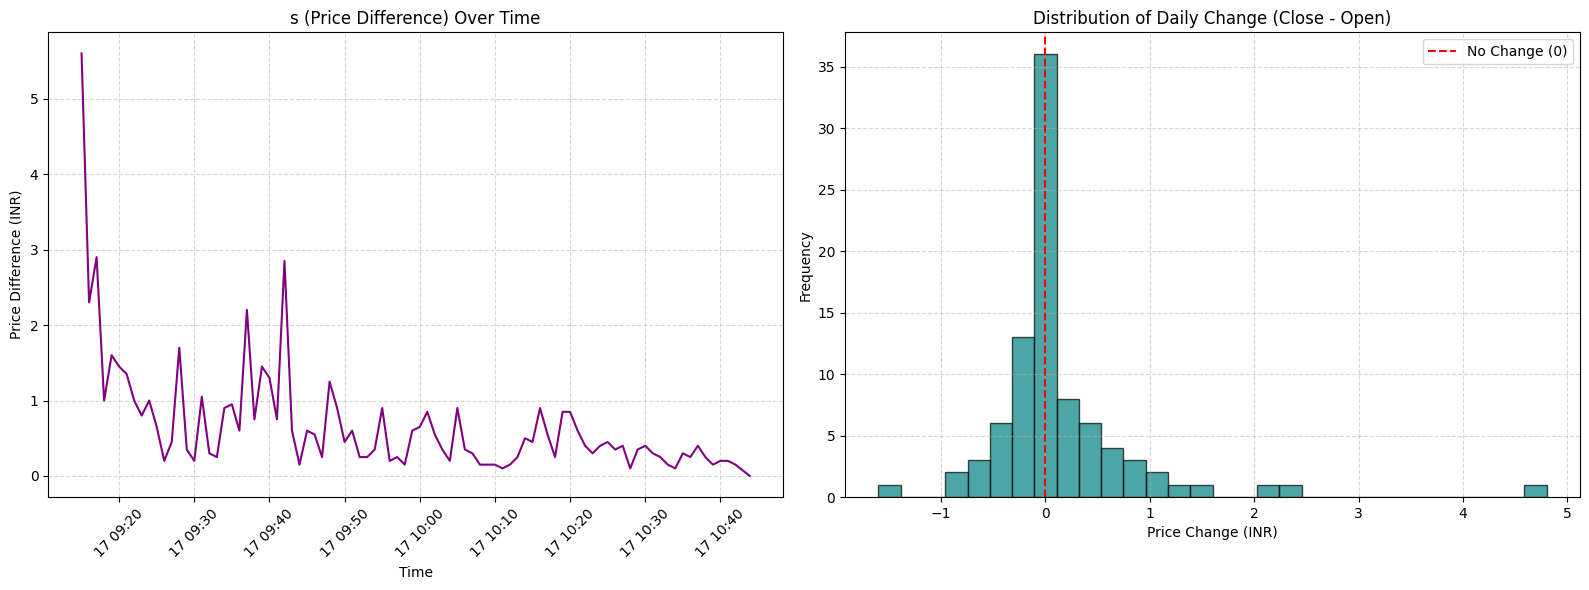

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].plot(df["Date"], df["Price_Diff"], color="purple", label="High - Low")
axes[0].set_title("s (Price Difference) Over Time")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Price Difference (INR)")
axes[0].grid(True, linestyle="--", alpha=0.5)
axes[0].tick_params(axis='x', rotation=45)

axes[1].hist(df["Daily_change"], bins=30, color="teal", edgecolor="black", alpha=0.7)
axes[1].axvline(0, color="red", linestyle="--", linewidth=1.5, label="No Change (0)")
axes[1].set_title("Distribution of Daily Change (Close - Open)")
axes[1].set_xlabel("Price Change (INR)")
axes[1].set_ylabel("Frequency")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [48]:
best_day = df["Close"].idxmax()

worst_day = df["Close"].idxmin()

print("Best Trading Day:")
print(df.loc[best_day])

print("Worst Trading Day:")
print(df.loc[worst_day])


Best Trading Day:
Date            2026-11-17 10:19:00+05:30
Open                           445.450012
High                           446.299988
Low                            445.450012
Close                          446.149994
Volume                            76751.0
Price_Diff                       0.849976
Daily_change                     0.699982
Name: 64, dtype: object
Worst Trading Day:
Date            2026-11-17 09:15:00+05:30
Open                           429.399994
High                                435.0
Low                            429.399994
Close                          434.200012
Volume                                0.0
Price_Diff                       5.600006
Daily_change                     4.800018
Name: 0, dtype: object
